##### 초기화

In [1]:
import json
import os

from IPython.display import Image, display

from graph import (
    build_graph,
    create_client,
    make_config,
    print_outcome,
    resume_turn,
    start_turn,
)
from nodes import AgentContext
from tools import reset_memory_store

In [2]:
client = create_client()
model = os.getenv("MODEL_NAME") or client.models.list().data[0].id

# 대화 State는 checkpointer가 thread_id별로 저장한다.
app = build_graph()
context = AgentContext(client=client, model=model)
reset_memory_store()

QUESTION = "2026년 해외 출장의 숙박비와 식비 한도, 출발 전 승인요건을 근거와 함께 정리해줘."
APPROVE_THREAD = "test-approve"
EDIT_THREAD = "test-edit"

In [3]:
def review(thread_id, decision):
    """사용자 입력(승인/수정)을 출력하고, 그 입력으로 멈춘 실행을 재개한다."""

    print("[사용자 입력]")
    print(json.dumps(decision, ensure_ascii=False, indent=2))

    outcome = resume_turn(app, context, thread_id, decision)

    # 수정이 받아들여졌으면 trace의 plan_reviewed 이벤트에 수정된 계획이 남는다.
    if outcome["status"] != "awaiting_review":
        reviewed = next(e for e in outcome["trace"] if e["event"] == "plan_reviewed")
        if reviewed["action"] == "edit":
            print("\n[수정된 계획]")
            for step in reviewed["plan"]:
                print(f"{step['id']}. {step['instruction']}  (depends_on={step['depends_on']})")

    print()
    print_outcome(outcome)
    return outcome

##### 그래프 구조

---
config:
  flowchart:
    curve: linear
---
graph TD;
	__start__([<p>__start__</p>]):::first
	planner(planner)
	plan_review(plan_review)
	executor(executor)
	progress_checker(progress_checker)
	replanner(replanner)
	final_answer(final_answer)
	update_summary(update_summary)
	__end__([<p>__end__</p>]):::last
	__start__ --> planner;
	executor -.-> final_answer;
	executor -.-> progress_checker;
	executor -.-> replanner;
	final_answer --> update_summary;
	plan_review -.-> executor;
	planner -.-> final_answer;
	planner -.-> plan_review;
	progress_checker -.-> executor;
	progress_checker -.-> final_answer;
	progress_checker -.-> replanner;
	replanner -.-> executor;
	replanner -.-> final_answer;
	update_summary --> __end__;
	plan_review -.-> plan_review;
	classDef default fill:#f2f0ff,line-height:1.2
	classDef first fill-opacity:0
	classDef last fill:#bfb6fc



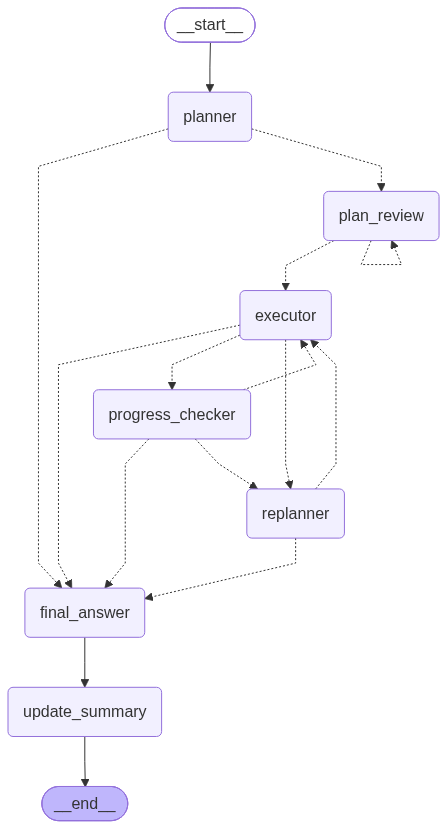

In [4]:
from IPython.display import Image, display
print(app.get_graph().draw_mermaid())
display(Image(app.get_graph().draw_mermaid_png()))

##### 테스트 1 — 계획 승인 후 실행
 - planner가 만든 계획에서 plan_review 노드가 멈춘다
 - `{"action": "approve"}`로 재개하면 그 계획 그대로 실행된다

In [5]:
outcome = start_turn(app, context, APPROVE_THREAD, QUESTION)
print_outcome(outcome)

[계획 검토 요청] 2026년 해외 출장의 숙박비와 식비 한도, 출발 전 승인요건을 근거와 함께 정리해줘.

1. 검색: 2026 년 해외 출장 관련 정책 문서에서 숙박비와 식비의 한도 기준을 찾아라.  (depends_on=[])
2. 검색: 2026 년 해외 출장 관련 정책 문서에서 출발 전 승인 요건과 근거를 찾아라.  (depends_on=[])
3. 추론: 검색된 숙박비/식비 한도 정보와 출발 전 승인 요건 정보를 종합하여 근거와 함께 정리하라.  (depends_on=[1, 2])


In [6]:
outcome = review(APPROVE_THREAD, {"action": "approve"})

[사용자 입력]
{
  "action": "approve"
}


Loading weights:   0%|          | 0/310 [00:00<?, ?it/s]

This model was loaded in torch.bfloat16 on CPU. Depending on your CPU, inference may be significantly slower than with torch.float32. Consider comparing inference speeds by loading with `model_kwargs={"dtype": torch.float32}`.




[completed / 4 LLM calls / 0 replans]

[Final Answer]

2026 년 해외 출장 관련 정책 정보를 근거와 함께 정리하면 다음과 같습니다.

**1. 숙박비 및 식비 한도 기준**
*   **숙박비**: 1 박당 최대 **220 달러**까지 청구 가능합니다.
    *   근거: `travel_lodging_B.txt` (2026 년, active 상태)
*   **식비**: 승인된 비즈니스 출장일 기준 1 일당 최대 **60 달러**까지 보상을 받습니다.
    *   근거: `meal_expense.txt` (2026 년, active 상태)

**2. 출발 전 승인 요건**
*   국제 비즈니스 출장 요청은 **출발 전에 부서장 (Department Head) 의 승인을 반드시 받아야** 합니다.
    *   근거: `travel_request.txt` (2026 년, active 상태)

상기 내용은 2026 년 현재 적용 중인 내부 정책 문서에서 확인된 사항입니다.

[Trace]

01. {"event": "turn_started", "goal": "2026년 해외 출장의 숙박비와 식비 한도, 출발 전 승인요건을 근거와 함께 정리해줘."}
02. {"event": "plan_created", "plan": [{"id": 1, "instruction": "검색: 2026 년 해외 출장 관련 정책 문서에서 숙박비와 식비의 한도 기준을 찾아라.", "depends_on": [], "status": "pending"}, {"id": 2, "instruction": "검색: 2026 년 해외 출장 관련 정책 문서에서 출발 전 승인 요건과 근거를 찾아라.", "depends_on": [], "status": "pending"}, {"id": 3, "instruction": "추론: 검색된 숙박비/식비 한도 정보와 출발 전 승인 요건 정보를 종합하여 근거와 함께 정리하라.", "depends_on": [1, 2], "

##### 테스트 2 — 계획 수정 후 실행
 - 같은 질문을 다른 thread에서 실행해, 테스트 1의 대화가 섞이지 않게 한다
 - 사용자가 계획을 직접 고쳐서 넘기면 수정된 계획으로 실행된다
 - 잘못 고치면 plan_review 노드가 다시 실행되어 재검토를 요청한다

In [7]:
outcome = start_turn(app, context, EDIT_THREAD, QUESTION)
print_outcome(outcome)

[계획 검토 요청] 2026년 해외 출장의 숙박비와 식비 한도, 출발 전 승인요건을 근거와 함께 정리해줘.

1. 검색: 2026 년 해외 출장 관련 정책 문서에서 숙박비와 식비의 한도 기준을 찾아라.  (depends_on=[])
2. 검색: 2026 년 해외 출장 관련 정책 문서에서 출발 전 승인 요건과 근거를 찾아라.  (depends_on=[])
3. 추론: 검색된 숙박비/식비 한도 정보와 출발 전 승인 요건 정보를 종합하여 정리하라.  (depends_on=[1, 2])


In [8]:
# 잘못된 수정: step 1이 뒤에 있는 step 2에 의존한다 → 검증 실패 → 다시 검토 요청
outcome = review(EDIT_THREAD, {
    "action": "edit",
    "steps": [
        {"instruction": "사내 문서에서 해외 출장 출발 전 승인 요건을 검색한다.", "depends_on": [2]},
        {"instruction": "사내 문서에서 2026년 기준 해외 출장 숙박비 한도와 식비 한도를 검색한다.", "depends_on": []},
    ],
})

[사용자 입력]
{
  "action": "edit",
  "steps": [
    {
      "instruction": "사내 문서에서 해외 출장 출발 전 승인 요건을 검색한다.",
      "depends_on": [
        2
      ]
    },
    {
      "instruction": "사내 문서에서 2026년 기준 해외 출장 숙박비 한도와 식비 한도를 검색한다.",
      "depends_on": []
    }
  ]
}

[계획 검토 요청] 2026년 해외 출장의 숙박비와 식비 한도, 출발 전 승인요건을 근거와 함께 정리해줘.

! 이전 수정이 거부됨: Plan step 1 has invalid dependencies.

1. 검색: 2026 년 해외 출장 관련 정책 문서에서 숙박비와 식비의 한도 기준을 찾아라.  (depends_on=[])
2. 검색: 2026 년 해외 출장 관련 정책 문서에서 출발 전 승인 요건과 근거를 찾아라.  (depends_on=[])
3. 추론: 검색된 숙박비/식비 한도 정보와 출발 전 승인 요건 정보를 종합하여 정리하라.  (depends_on=[1, 2])


In [9]:
# 올바른 수정: 숙박비, 식비, 승인 요건을 각각 검색하는 step 세 개로 나눈다
outcome = review(EDIT_THREAD, {
    "action": "edit",
    "steps": [
        {"instruction": "사내 문서에서 2026년 기준 해외 출장 숙박비 한도를 검색한다. active 문서를 우선한다.", "depends_on": []},
        {"instruction": "사내 문서에서 2026년 기준 해외 출장 식비 한도를 검색한다. active 문서를 우선한다.", "depends_on": []},
        {"instruction": "사내 문서에서 해외 출장 출발 전 승인 요건을 검색한다.", "depends_on": []},
    ],
})

[사용자 입력]
{
  "action": "edit",
  "steps": [
    {
      "instruction": "사내 문서에서 2026년 기준 해외 출장 숙박비 한도를 검색한다. active 문서를 우선한다.",
      "depends_on": []
    },
    {
      "instruction": "사내 문서에서 2026년 기준 해외 출장 식비 한도를 검색한다. active 문서를 우선한다.",
      "depends_on": []
    },
    {
      "instruction": "사내 문서에서 해외 출장 출발 전 승인 요건을 검색한다.",
      "depends_on": []
    }
  ]
}

[수정된 계획]
1. 사내 문서에서 2026년 기준 해외 출장 숙박비 한도를 검색한다. active 문서를 우선한다.  (depends_on=[])
2. 사내 문서에서 2026년 기준 해외 출장 식비 한도를 검색한다. active 문서를 우선한다.  (depends_on=[])
3. 사내 문서에서 해외 출장 출발 전 승인 요건을 검색한다.  (depends_on=[])


[completed / 4 LLM calls / 0 replans]

[Final Answer]

2026 년 해외 출장 관련 비용 한도 및 승인 요건은 다음과 같습니다.

**1. 비용 한도**
*   **숙박비**:每晚 (하루) **220 달러**까지 청구 가능합니다.
    *   근거: `travel_lodging_B.txt` (2026 년, active)
*   **식비**: 하루 **60 달러**까지 정산됩니다.
    *   근거: `meal_expense.txt` (2026 년, active)

**2. 출발 전 승인 요건**
*   해외 출장 출발 전에는 반드시 **부서장 (Department Head)** 의 승인이 필요합니다.
    *   근거: `travel_request.txt` (2026 년, active)

모든 관

##### 같은 대화 이어가기 — 요약
 - 테스트 2와 같은 thread_id로 턴을 이어가면 Planner가 이전 대화를 본다
 - 세 번째 턴이 끝나면 최근 2턴보다 오래된 첫 턴이 요약된다

In [10]:
outcome = start_turn(app, context, EDIT_THREAD, "방금 정리한 내용 중에서 숙박비 한도만 다시 알려줘.")
print_outcome(outcome)

[계획 검토 요청] 방금 정리한 내용 중에서 숙박비 한도만 다시 알려줘.

1. Search internal company documents for the 2026 overseas travel lodging expense limit.  (depends_on=[])
2. Read the document found in step 1 to extract the specific lodging limit amount and its validity status.  (depends_on=[1])


In [11]:
outcome = review(EDIT_THREAD, {"action": "approve"})

[사용자 입력]
{
  "action": "approve"
}


[completed / 2 LLM calls / 0 replans]

[Final Answer]

2026 년 해외 출장의 숙박비 한도는 **每晚 (하루) 220 달러**입니다.

*   근거: `travel_lodging_B.txt` (2026 년, active)

[Trace]

01. {"event": "turn_started", "goal": "방금 정리한 내용 중에서 숙박비 한도만 다시 알려줘."}
02. {"event": "plan_created", "plan": [{"id": 1, "instruction": "Search internal company documents for the 2026 overseas travel lodging expense limit.", "depends_on": [], "status": "pending"}, {"id": 2, "instruction": "Read the document found in step 1 to extract the specific lodging limit amount and its validity status.", "depends_on": [1], "status": "pending"}]}
03. {"event": "plan_reviewed", "action": "approve"}
04. {"event": "plan_step_started", "plan_step_id": 1, "instruction": "Search internal company documents for the 2026 overseas travel lodging expense limit.", "depends_on": []}
05. {"event": "agent_loop_iteration", "plan_step_id": 1, "iteration": 1, "tool_call_count": 1}
06. {"event": "tool_called", "plan_step_id"

In [12]:
outcome = start_turn(app, context, EDIT_THREAD, "식비 한도도 다시 알려줘.")
print_outcome(outcome)

[계획 검토 요청] 식비 한도도 다시 알려줘.

1. search internal company documents for 'meal_expense.txt' to retrieve the 2026 daily meal allowance limit and its validity status.  (depends_on=[])
2. reason over the evidence found in step 1 to extract the specific dollar amount for the 2026 meal limit and confirm it is active.  (depends_on=[1])


In [13]:
outcome = review(EDIT_THREAD, {"action": "approve"})

[사용자 입력]
{
  "action": "approve"
}


[completed / 4 LLM calls / 1 replans]

[Final Answer]

2026 년 해외 출장의 식비 한도는 **하루 60 달러**입니다.

*   근거: `meal_expense.txt` (2026 년, active)

[Trace]

01. {"event": "turn_started", "goal": "식비 한도도 다시 알려줘."}
02. {"event": "plan_created", "plan": [{"id": 1, "instruction": "search internal company documents for 'meal_expense.txt' to retrieve the 2026 daily meal allowance limit and its validity status.", "depends_on": [], "status": "pending"}, {"id": 2, "instruction": "reason over the evidence found in step 1 to extract the specific dollar amount for the 2026 meal limit and confirm it is active.", "depends_on": [1], "status": "pending"}]}
03. {"event": "plan_reviewed", "action": "approve"}
04. {"event": "plan_step_started", "plan_step_id": 1, "instruction": "search internal company documents for 'meal_expense.txt' to retrieve the 2026 daily meal allowance limit and its validity status.", "depends_on": []}
05. {"event": "agent_loop_iteration", "plan_step_id

##### checkpointer에 저장된 State

In [14]:
config = make_config(EDIT_THREAD)
saved = app.get_state(config).values

for turn in saved["turns"]:
    print("user     :", turn[0]["content"])
    print("assistant:", turn[1]["content"][:80], "...\n")
print("summary:", saved["summary"])

user     : 2026년 해외 출장의 숙박비와 식비 한도, 출발 전 승인요건을 근거와 함께 정리해줘.
assistant: 2026 년 해외 출장 관련 비용 한도 및 승인 요건은 다음과 같습니다.

**1. 비용 한도**
*   **숙박비**:每晚 (하루) **220 ...

user     : 방금 정리한 내용 중에서 숙박비 한도만 다시 알려줘.
assistant: 2026 년 해외 출장의 숙박비 한도는 **每晚 (하루) 220 달러**입니다.

*   근거: `travel_lodging_B.txt` (20 ...

user     : 식비 한도도 다시 알려줘.
assistant: 2026 년 해외 출장의 식비 한도는 **하루 60 달러**입니다.

*   근거: `meal_expense.txt` (2026 년, activ ...

summary: ### 요약된 중요 정보

**1. 비용 한도 (2026 년 기준)**
*   **숙박비**: 하루 **220 달러**
*   **식비**: 하루 **60 달러**

**2. 출발 전 승인 요건**
*   **필수 승인자**: 부서장 (Department Head)
*   **시기**: 해외 출장 출발 전

**3. 문서 유효성**
*   관련 정책 문서 (`travel_lodging_B.txt`, `meal_expense.txt`, `travel_request.txt`) 는 모두 **2026 년 기준 'active' (유효)** 상태입니다.


In [15]:
# checkpoint 기록: 노드가 끝날 때마다 하나씩 저장된다 (최신 → 과거 순)
for snapshot in app.get_state_history(config):
    paused = "  ← interrupt: 계획 검토 대기" if snapshot.interrupts else ""
    print(f"step {snapshot.metadata['step']:>3}  next={snapshot.next}{paused}")

step  30  next=()
step  29  next=('update_summary',)
step  28  next=('final_answer',)
step  27  next=('progress_checker',)
step  26  next=('executor',)
step  25  next=('replanner',)
step  24  next=('progress_checker',)
step  23  next=('executor',)
step  22  next=('plan_review',)  ← interrupt: 계획 검토 대기
step  21  next=('planner',)
step  20  next=('__start__',)
step  19  next=()
step  18  next=('update_summary',)
step  17  next=('final_answer',)
step  16  next=('progress_checker',)
step  15  next=('executor',)
step  14  next=('plan_review',)  ← interrupt: 계획 검토 대기
step  13  next=('planner',)
step  12  next=('__start__',)
step  11  next=()
step  10  next=('update_summary',)
step   9  next=('final_answer',)
step   8  next=('progress_checker',)
step   7  next=('executor',)
step   6  next=('progress_checker',)
step   5  next=('executor',)
step   4  next=('progress_checker',)
step   3  next=('executor',)
step   2  next=('plan_review',)  ← interrupt: 계획 검토 대기
step   1  next=('plan_review',)  ← 

##### 테스트 3 — 재계획(Replan) 발생 사례
 - progress_checker가 `replan` 결정 → replanner 노드 실행 → 새 계획으로 이어가는 흐름
 - 위 "식비 한도" 테스트에서 자연스럽게 발생했지만, 아래는 의도적으로 유도하는 예시
 - trace에서 `plan_revised` 이벤트와 `replans` 카운트 확인

In [16]:
# 재계획 테스트: 존재하지 않는 정책을 물어 첫 step 실패 → replan 유도
REPLAN_THREAD = "test-replan"
reset_memory_store()

outcome = start_turn(app, context, REPLAN_THREAD, "XYZ-999 정책의 세부 조항을 알려줘.")
print_outcome(outcome)

[계획 검토 요청] XYZ-999 정책의 세부 조항을 알려줘.

1. 내부 회사 문서에서 'XYZ-999' 정책의 세부 조항을 검색하세요.  (depends_on=[])


In [17]:
# 승인 후 실행: 검색 실패 시 replan 발생 여부 확인
outcome = review(REPLAN_THREAD, {"action": "approve"})

# replan 발생 확인
replan_events = [e for e in outcome["trace"] if e["event"] == "plan_revised"]
print(f"\n[Replan 발생 횟수: {len(replan_events)}]")
for e in replan_events:
    print(f"  사유: {e['reason']}")

[사용자 입력]
{
  "action": "approve"
}


[completed / 6 LLM calls / 2 replans]

[Final Answer]

내부 문서에 'XYZ-999' 정책의 정식 명칭이나 관련 키워드가 존재하지 않습니다. 요청하신 정책의 세부 조항에 대한 정보는 누락되어 있어 확인이 불가능합니다.

[Trace]

01. {"event": "turn_started", "goal": "XYZ-999 정책의 세부 조항을 알려줘."}
02. {"event": "plan_created", "plan": [{"id": 1, "instruction": "내부 회사 문서에서 'XYZ-999' 정책의 세부 조항을 검색하세요.", "depends_on": [], "status": "pending"}]}
03. {"event": "plan_reviewed", "action": "approve"}
04. {"event": "plan_step_started", "plan_step_id": 1, "instruction": "내부 회사 문서에서 'XYZ-999' 정책의 세부 조항을 검색하세요.", "depends_on": []}
05. {"event": "agent_loop_iteration", "plan_step_id": 1, "iteration": 1, "tool_call_count": 1}
06. {"event": "tool_called", "plan_step_id": 1, "tool": "search_documents", "arguments": {"query": "'XYZ-999' 정책의 세부 조항", "status_filter": "active"}, "result_summary": {"status": "no_results", "note": "No documents scored above the relevance threshold. Rephrase the query once, or state that the information is not avai